# Multispectral / multiparametric MRI

**`02-mri-intro.ipynb`** - BMED365 / Lab4-Comp-Imag <br>


Last update: 2026-02-08

(Using the uv environment bmed365-2027 in [pyproject.toml](../pyproject.toml))

<a href="https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/02-mri-intro.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Learning objectives:

**Illustration of multiparametric and multispectral MR images in space and time**

- You will learn that **multispectral** MRI and **multiparametric** MRI denote the same concept: **every pixel (or voxel) has vectorial values** where each component in the [vector](https://en.wikipedia.org/wiki/Vector_(mathematics_and_physics)) represents signal intensity (at that location) in a specific MRI pulse sequence (typical for [multispectral](https://en.wikipedia.org/wiki/Multispectral_image) MRI), or an image-derived parameter value e.g. physiologcal, biochemical, or [textural](https://en.wikipedia.org/wiki/Image_texture) features (typical for multiparametric MRI, or in [radiomics](https://en.wikipedia.org/wiki/Radiomics)).

 
- You will also get **insight into representation** and **manipulation of digital images**: image formats (DICOM, NIFTI, PNG); [binary](https://en.wikipedia.org/wiki/Binary_image) (0/1) images, [grayscale](https://en.wikipedia.org/wiki/Grayscale) images and RGB [color](https://en.wikipedia.org/wiki/Color_image) images; different **[data types](https://en.wikipedia.org/wiki/Data_type)** (float, uint8, RGB) of images; and anatomical orientation (geometry) of recorded images - which is important in medical images   (e.g. up-down, left-right, anterior-posterior) cf. the [standard anatomical position](https://en.wikipedia.org/wiki/Standard_anatomical_position).

In [ ]:
# This is a quick check of whether the notebook is currently running on Google Colaboratory, as that makes some difference for the code below.
# We'll do this in every notebook of the course.
if 'google.colab' in str(get_ipython()):
    print('The notebook is running on Colab. colab=True.')
    colab=True
    # Some libraries will be necessary to "pip install" on colab:
    !pip install nilearn
    !pip installe templateflow
else:
    print('The notebook is not running on Colab. colab=False.')
    colab=False

The notebook is not running on Colab. colab=False.


**Download zipped data from Google Drive using gdown**

In [7]:
import gdown
import shutil
import os
import sys

In [8]:
if os.path.isdir('./assets') == False:
    
    ## Download assets.zip from Google Drive (My Drive -> BMED365 -> Lab-optional-imaging -> assets.zip)
    # https://drive.google.com/file/d/1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN/view?usp=share_link
    
    file_id = '1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN'
    url = 'https://drive.google.com/uc?id=%s' % file_id
    output = './assets.zip'
    #gdown.download(url, output, quiet=False)
    !gdown "1yYoQZR8jSyL1_23wimkMDHQv3cGC8TWN&confirm=t"
    
    ## Unzip the assets.zip file into `./assets`
    shutil.unpack_archive(output, '.')
    
    ## Delete the `assets.zip` file
    os.remove(output)
else:
    print(f'./assets  exists already and will not be overwritten!')

./assets  exists already and will not be overwritten!


In [9]:
if os.path.isdir('./data') == False:
    
    ## Download data.zip from Google Drive  (My Drive -> BMED365 -> Lab-optional-imaging -> data.zip)
    # https://drive.google.com/file/d/1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c/view?usp=share_link
    
    file_id = '1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c'
    url = 'https://drive.google.com/uc?id=%s' % file_id
    output = './data.zip'
    #gdown.download(url, output, quiet=False)
    !gdown "1mKbERWG09Ni5UpnYhLlcebKfxeVu_Y2c&confirm=t"
    
    ## Unzip the data.zip file into `./data`
    shutil.unpack_archive(output, '.')
    
    ## Delete the `data.zip` file
    os.remove(output)
else:
    print(f'./data  exists already and will not be overwritten!')

./data  exists already and will not be overwritten!


### Import labraries

In [10]:
import json
import errno
import zipfile
import pandas as pd
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from pandas.core.common import flatten
import imageio
import skimage
from skimage import io
import nibabel as nib
from nibabel.viewers import OrthoSlicer3D
import nilearn
from nilearn import plotting
import templateflow
import templateflow.api as tflow
import warnings  

# To display plots directly in the notebook:
%matplotlib inline


In [11]:
print('Python version ' + sys.version)
print('Pandas version ' + pd.__version__)
print('Numpy version ' + np.__version__)
print('Matplotlib version ' + matplotlib.__version__)
print('Seaborn version ' + sns.__version__)
print('Imageio version ' + imageio.__version__)
print('Scikit-image version ' + skimage.__version__)
print('Nibabel version ' + nib.__version__)
print('Nlearn version ' + nilearn.__version__)
print('Templateflow version ' + templateflow.__version__)

Python version 3.10.19 | packaged by conda-forge | (main, Jan 26 2026, 23:57:06) [Clang 19.1.7 ]
Pandas version 2.3.3
Numpy version 2.2.6
Matplotlib version 3.10.8
Seaborn version 0.13.2
Imageio version 2.37.0
Scikit-image version 0.25.2
Nibabel version 5.3.2
Nlearn version 0.13.0
Templateflow version 25.1.1


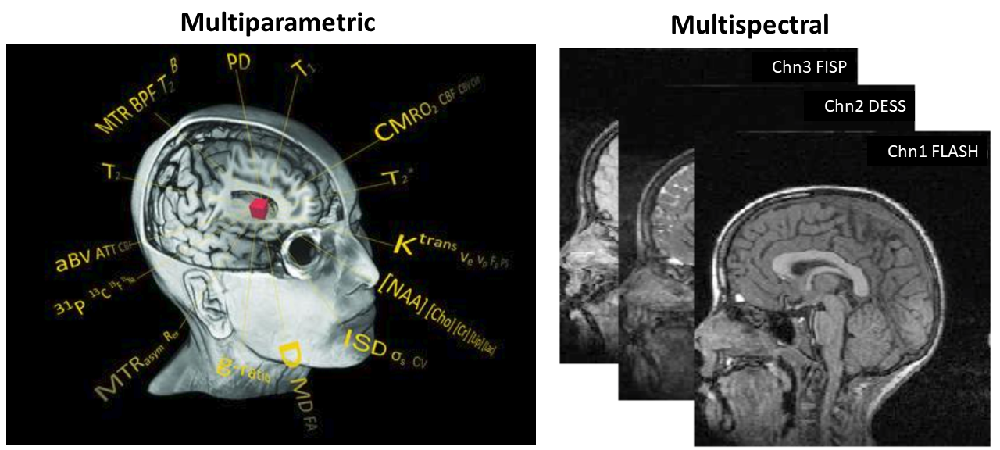

In [12]:
from IPython.display import Image
Image(filename='./assets/mpMRI_figure_pptx.png', width=800)

## Image information can be in SPACE  (2D or 3D)

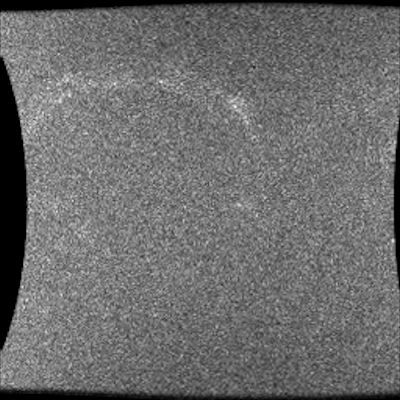

In [13]:
from IPython.display import Image
Image(filename='./assets/3DT1_spgr_out_of_phase_2_2_mov.gif.png', width=400)

## Image information can be in SPACE-TIME (2D+time or 3D+time)

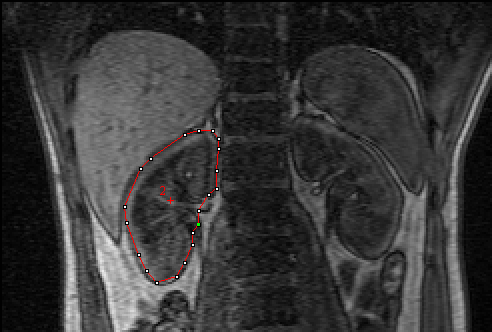

In [14]:
from IPython.display import Image
Image(filename='./assets/kidney_slice10_frame10_roi_avi_ezgif.com-video-to-gif.gif.png', width=400)

## $\rightarrow$ Your turn!

- Which anatomical region is depicted here?


- Try to identify the organs and structures in this 3D+time image, remember Google is your friend (here we see slice 10 only)

 - Liver
 - Spleen
 - Kidney
 - Spine
 - Intervertebral discs
 - Muscle
 - Fat
 

- What is the anatomical orientation of the image?


- Which structures are basically stationary (not moving) during the 3D+time recording?


- Which structures are moving?

  - In what way?
  - Why?
  
  
- For a given voxel $v_p$ in the 3D+time image, with coordinates $p=(i,j,k)$ we see signal intensity (SI) changes over time, especially in the kidneys. These local SI changes can be decomposed into two phenomena (or dynamics).
 - One component is due to organ motion (displacement), can you explain the other dynamics?

## Image information can be multiparametric

The figure show MRI examination (**mpMRI**) and statistical analysis in [prostate cancer](https://en.wikipedia.org/wiki/Prostate_cancer) (PCa)<br>
[ from Chaddad et al. [Predicting Gleason Score of Prostate Cancer Patients Using Radiomic Analysis](https://www.frontiersin.org/articles/10.3389/fonc.2018.00630/full), Frontiers in Oncology, 18 Dec 2018 ]

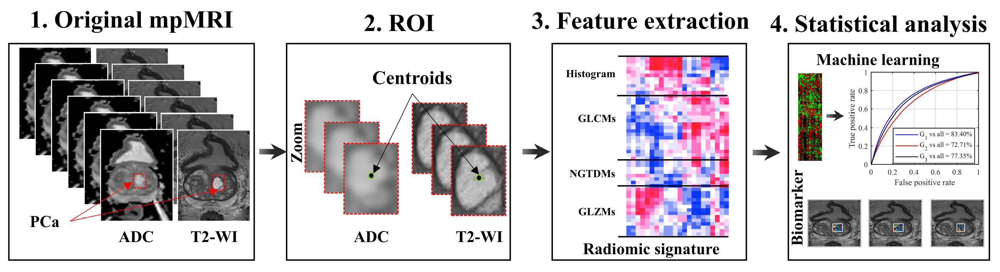

In [15]:
from IPython.display import Image
Image(filename='./assets/chaddad_etal_2018_fig1.png', width=900)

# Four-channel multispectral image (X) and training masks (y)

We will study a **multispectral image** (slice 60 from a multispectral 3D recording),
reported in  Lundervold et al. Volume distribution of cerebrospinal fluid using multispectral MR
imaging. *Medical Image Analysis* 2000;4:123-136. https://www.ncbi.nlm.nih.gov/pubmed/10972326 <br>
and a manually delineated **training mask** with 6 tissue types, or classes (color-coded in [R,G,B] space) as follows: 

 | Class | Description          | Color   | RGB-values  |
 |:-----:|:--------------------|:--------|:-----------|
 | AIR | air/cortical bone   | Magenta | [255,0,255] |
 | GM  | grey matter         | Red     | [255,0,0]   |
 | WM  | white matter        | Cyan    | [0,255,255] |
 | CSF | cerebrospinal fluid | Blue    |  [0,0,255]  |
 | MUS | muscle              | Green   | [0,255,0]   |
 | FAT | fat                 | Yellow  | [255,255,0] |
 
 
**$\rightarrow$ CHECK OUT!**<br> *Multispectral MRI analysis started with the seminal work of [Vannier et al.](https://www.ncbi.nlm.nih.gov/pubmed/3964938), Radiology 1985 - inspired by research at NASA!*

**The Figure below shows manual color-coded labeling of pixels belonging to six different tissue types (classes, or labels) and the corresponding multispectral MRI recording**<br>

- Predefined tissue types (**labels**), denoted $y$:  air/bone - AIR, grey matter - GM, white matter - WM, cerebrospinal fluid - CSF,  muscle - MUS, fat - FAT<br>

- Channels/pulse sequences (**feature vectors**), or simly **data**, denoted $X$:  FLASH ($X_1$), DESS ($X_2$), FISP ($X_3$), PSIF ($X_ 4$)

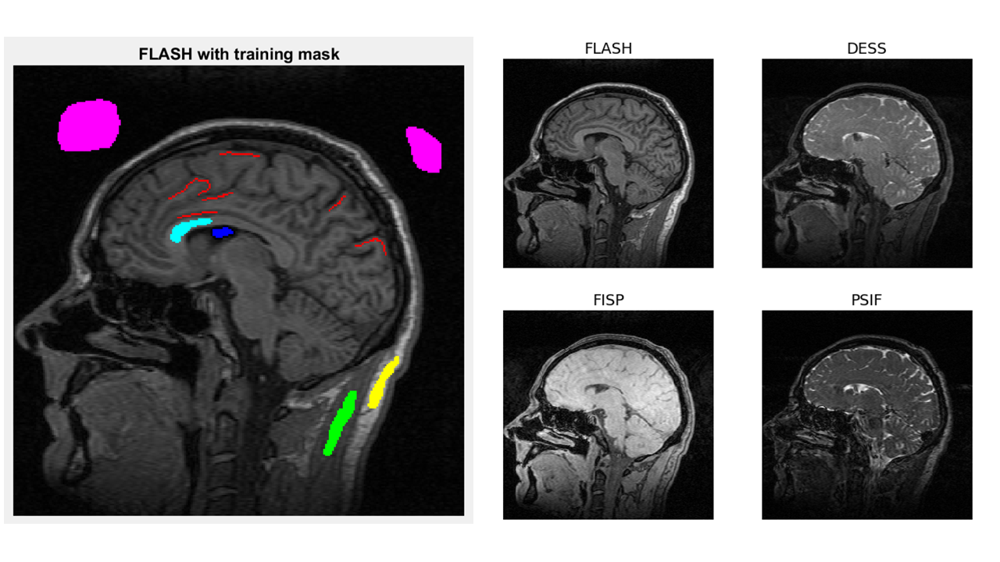

In [16]:
from IPython.display import Image
Image(filename='./assets/multispectral_tissue_classification_pptx.png', width=600)

## MRI pulse sequences

**Specify data directory, channel names ([MRI pulse sequences](https://radiopaedia.org/articles/mri-pulse-sequences-1)) and class names = [tissue types](https://en.wikipedia.org/wiki/Tissue_(biology))**

[MRI pulse sequence abbreviations](https://radiopaedia.org/articles/mri-pulse-sequence-abbreviations):

 - FLASH - Fast Low Angle Shot [[ref](https://en.wikipedia.org/wiki/Fast_low_angle_shot_magnetic_resonance_imaging)]
 - DESS - Double Echo Steady State [[ref](http://mriquestions.com/dess.html)]
 - FISP - Fast Imaging with Steady-state free Precession [[ref](http://mriquestions.com/psif-vs-fisp.html)]
 - PSIF - revers FISP

In [17]:
mydata = './data/mri'
chn_names = ['FLASH', 'DESS', 'FISP', 'PSIF']
class_names = ['air', 'gm', 'wm', 'csf', 'mus', 'fat']

# Construct a multispectral image

**Initialize a list and populate it by looping through named and compressed [NIFTI](https://nifti.nimh.nih.gov) files ( .nii.gz) being the channel images**

In [18]:
k=1
images = []  # for making a sequence of channel images
for fn in chn_names:
    cmd = 'img%d = nib.load("%s/%s_060.nii.gz")' % (k, mydata, fn.lower())
    exec(cmd)
    print(cmd)
    cmd = 'images.append(img%d)' % (k); exec(cmd)
    k=k+1

img1 = nib.load("./data/mri/flash_060.nii.gz")
img2 = nib.load("./data/mri/dess_060.nii.gz")
img3 = nib.load("./data/mri/fisp_060.nii.gz")
img4 = nib.load("./data/mri/psif_060.nii.gz")


Alternatively:

In [19]:
images = []  # for making a sequence of channel images
for k, fn in enumerate(chn_names):
    cmd = 'img%d = nib.load("%s/%s_060.nii.gz")' % (k+1, mydata, fn.lower())
    exec(cmd)
    print(cmd)
    cmd = 'images.append(img%d)' % (k+1); exec(cmd)
print('Number of images:', len(images))

img1 = nib.load("./data/mri/flash_060.nii.gz")
img2 = nib.load("./data/mri/dess_060.nii.gz")
img3 = nib.load("./data/mri/fisp_060.nii.gz")
img4 = nib.load("./data/mri/psif_060.nii.gz")
Number of images: 4


Another way to read NIFTI images from disk (a "one-liner" using list comprehension):

In [20]:
images = [nib.load(f'{mydata}/{channel.lower()}_060.nii.gz') for channel in chn_names]
print('Number of images:', len(images))

Number of images: 4


**We use `nibabel's` [concat_images](http://nipy.org/nibabel/reference/nibabel.funcs.html#nibabel.funcs.concat_images) to construct a multispectral image from the $k$ constituent channel images, each with the same $n \times n$ image matrix (and geometry)**

*Tip:* check the options of `nibabel` by writing `nib.` and then press the `tab` key

**Concatenate the cannel images to one multispectral image**

In [21]:
# Concatenate images
img_mult = nib.concat_images(images)

## NOTE on scanner (world) coordinates, anatomical references, and image matrix 

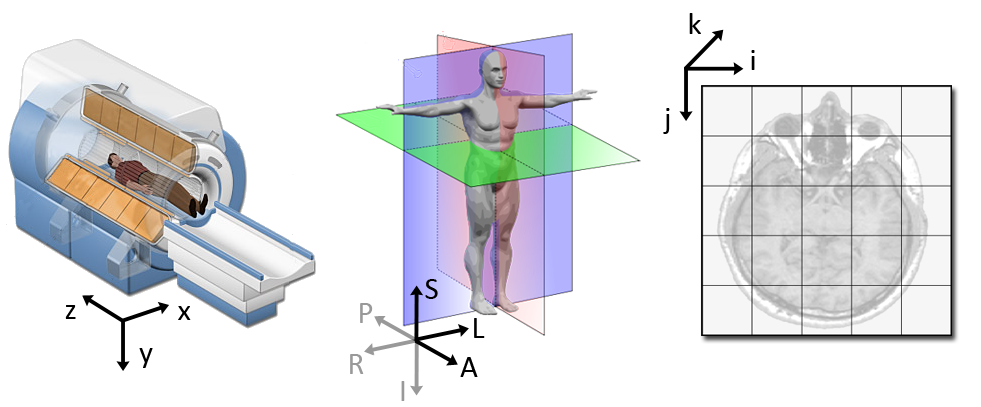

In [22]:
from IPython.display import Image
Image(filename='./assets/Coordinate_systems.png', width=800)

**Figure** from https://www.slicer.org.  See [this](https://www.slicer.org/wiki/Coordinate_systems) link for more information, and [here](http://www.grahamwideman.com/gw/brain/orientation/orientterms.htm) and [here](http://dicom.nema.org/dicom/2013/output/chtml/part03/sect_C.7.html#sect_C.7.6.2.1.1) and [here](https://nifti.nimh.nih.gov/nifti-1/documentation/faq) and [here](http://people.cs.uchicago.edu/~glk/unlinked/nrrd-iomf.pdf) and the [[dcm2nii](https://www.nitrc.org/plugins/mwiki/index.php/dcm2nii:MainPage)]

## Open access to templates - TemplateFlow


We can download (template) images from https://www.templateflow.org according to **FAIR** principles


<div style="display: flex; justify-content: left;">
    (<b>a</b>) &nbsp; <img src="https://www.templateflow.org/assets/templateflow_fig-templates.png" width="400" style="margin-right: 50px;">
    (<b>b</b>) &nbsp; <img src="https://www.templateflow.org/assets/templateflow_fig-birdsview.png" width="400">
</div>

(**a**) The 7 templates highlighted in blue are constituents of the Montreal Neurological Institute (MNI) portfolio. The Waxholm space (WHS) and Fischer344 templates provide references for rat neuroimaging. fsaverage and fsLR are surface templates; the remaining templates are volumetric. Each template is distributed with atlas labels, segmentations, and metadata files. The 15 templates displayed here are only a small fraction of those created as stereotaxic references for the neuroimaging community.

(**b**) TemplateFlow implements the **FAIR** * guiding principles. The TemplateFlow Archive can be accessed at a “low” level with DataLad, or at a “high” level with a Python client. New resources can be added through the TemplateFlow Manager Command Line Interface, which initiates a peer-review process before acceptance in the Archive.

*) The FAIR principles are guidelines for scientific data management and stewardship:

**F**indable:
- Data has globally unique, persistent identifiers
- Rich metadata describing the data
- Metadata/data registered in searchable resources

**A**ccessible:
- Data retrievable via standardized protocols
- Authentication/authorization when necessary
- Metadata remains accessible even if data isn't

**I**nteroperable:
- Data uses formal, accessible, shared language
- Vocabularies follow FAIR principles
- Qualified references to other data

**R**eusable:
- Clear usage licenses
- Detailed provenance
- Domain-relevant community standards

These principles aim to make research data machine-readable and reusable by both humans and computational systems.

100%|██████████| 13.7M/13.7M [00:01<00:00, 11.7MB/s]


Affine Matrix:
[[   1.    0.    0.  -96.]
 [   0.    1.    0. -132.]
 [   0.    0.    1.  -78.]
 [   0.    0.    0.    1.]]

Image Shape: (193, 229, 193)


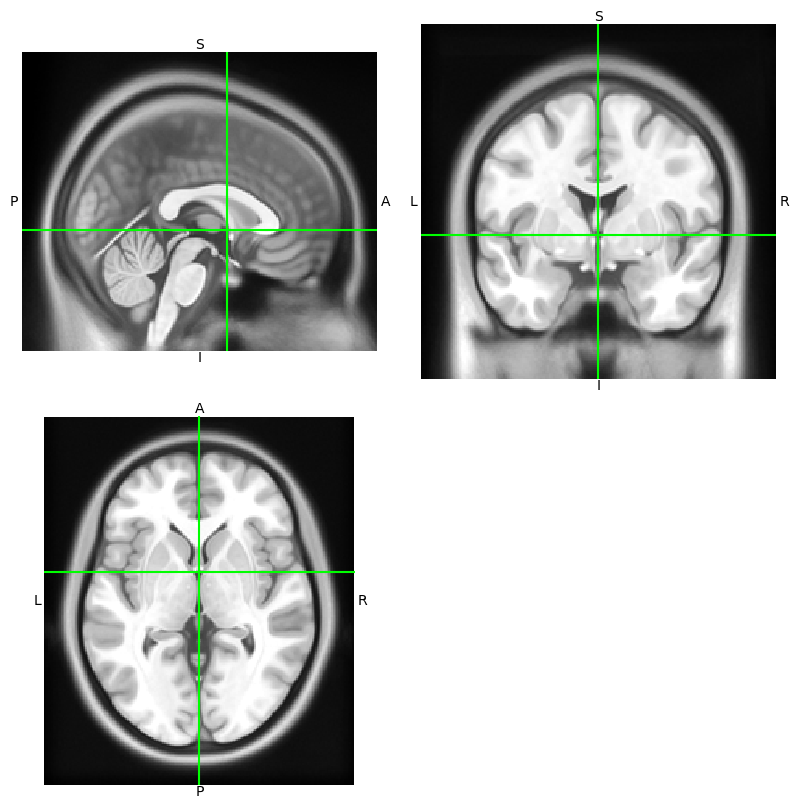

In [23]:
# Get the template path
T1w = tflow.get('MNI152NLin2009cAsym', desc=None, resolution=1, suffix='T1w', extension='nii.gz')

# Load the NIfTI file using nibabel
T1w_img = nib.load(str(T1w))  # Convert PosixPath to string

# Display the template with affine information
print("Affine Matrix:")
print(T1w_img.affine)
print("\nImage Shape:", T1w_img.shape)

# Display orthogonal slices
OrthoSlicer3D(T1w_img.get_fdata(), affine=T1w_img.affine, title="MNI152").show()


## An example of k-space and MR image reconstruction and the relationship between them

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift

In [25]:
# Create a simple phantom image
def create_phantom(size=256):
    phantom = np.zeros((size, size))
    center = size // 2
    
    # Create a circular object
    y, x = np.ogrid[-center:size-center, -center:size-center]
    mask = x*x + y*y <= (size//3)**2
    phantom[mask] = 1
    
    # Add some internal structure
    phantom[center-20:center+20, center-20:center+20] = 0.5
    
    return phantom

phantom = create_phantom()


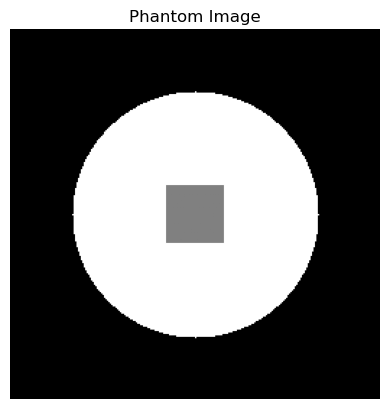

In [26]:
# Display the phantom image
plt.imshow(phantom, cmap='gray')
plt.title('Phantom Image')
plt.axis('off')
plt.show()


In [27]:
# Simulate k-space data
k_space = fftshift(fft2(phantom))


In [28]:
def reconstruct_and_visualize(k_space, title):
    # Reconstruct image from k-space

    reconstructed = np.abs(ifft2(ifftshift(k_space)))
    
    # Visualize
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.imshow(np.log(np.abs(k_space)), cmap='gray')
    ax1.set_title('K-space (log scale)')
    ax1.axis('off')
    
    ax2.imshow(reconstructed, cmap='gray')
    ax2.set_title('Reconstructed Image')
    ax2.axis('off')
    
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

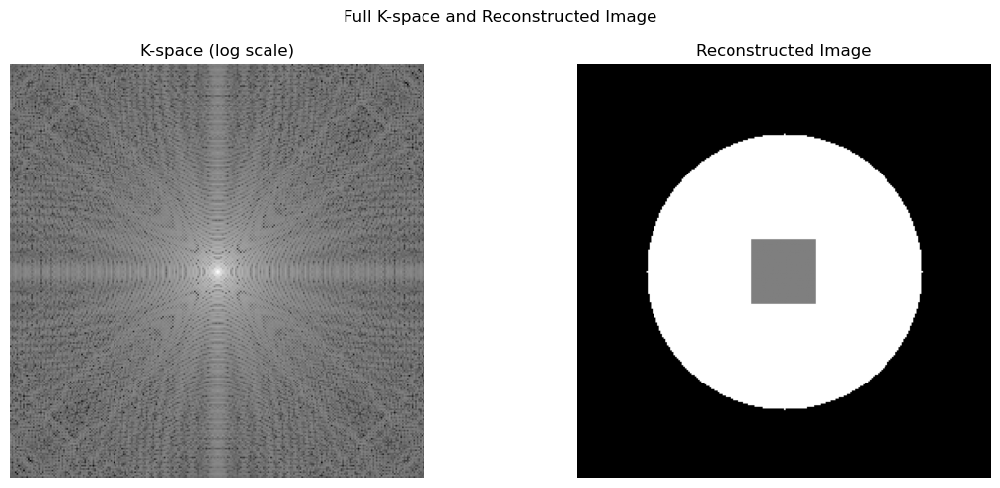

In [29]:
# Visualize full k-space and reconstructed image
reconstruct_and_visualize(k_space, "Full K-space and Reconstructed Image")


### Demonstrating K-space Properties


In [30]:
def eliminate_low_frequencies(image):
    """
    Demonstrate low frequency elimination in k-space with step-by-step visualization
    """

    
    # Create figure for step-by-step visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    ax = axes.ravel()
    
    # 1. Original image
    ax[0].imshow(image, cmap='gray')
    ax[0].set_title('(A) Original Image')
    print("Step 1: Loaded original image")
    
    # 2. Convert to k-space
    k_space = np.fft.fftshift(np.fft.fft2(image))
    ax[1].imshow(np.log(1 + np.abs(k_space)), cmap='gray')
    ax[1].set_title('(B) K-space (log scale)')
    print("Step 2: Converted to k-space")
    
    # 3. Create high-pass filter mask
    center = np.array(k_space.shape) // 2
    mask = np.ones_like(k_space, dtype=float)  # Changed to float
    radius = 32  # Size of low frequency region to remove
    y, x = np.ogrid[-center[0]:k_space.shape[0]-center[0],
                    -center[1]:k_space.shape[1]-center[1]]
    mask_area = x*x + y*y <= radius*radius
    mask[mask_area] = 0  # Remove low frequencies
    ax[2].imshow(mask, cmap='gray')  # Now displaying real values
    ax[2].set_title('(C) High-pass Filter Mask')
    print("Step 3: Created high-pass filter mask")
    
    # 4. Apply mask to k-space
    k_space_filtered = k_space * mask
    ax[3].imshow(np.log(1 + np.abs(k_space_filtered)), cmap='gray')
    ax[3].set_title('(D) Filtered K-space')
    print("Step 4: Applied high-pass filter")
    
    # 5. Inverse FFT to get filtered image
    image_filtered = np.abs(np.fft.ifft2(np.fft.ifftshift(k_space_filtered)))
    ax[4].imshow(image_filtered, cmap='gray')
    ax[4].set_title('(E) High-pass Filtered Image')
    print("Step 5: Reconstructed filtered image")
    
    # 6. Show difference (removed low frequencies)
    difference = image - image_filtered
    ax[5].imshow(difference, cmap='gray')
    ax[5].set_title('Difference image A-E (removed low frequencies)')
    print("Step 6: Computed difference image")
    
    # Turn off axes
    for a in ax:
        a.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("\nFrequency Domain Statistics:")
    print(f"Original k-space max magnitude: {np.abs(k_space).max():.1f}")
    print(f"Filtered k-space max magnitude: {np.abs(k_space_filtered).max():.1f}")
    print(f"Percentage of frequencies removed: {100 * (1 - np.sum(mask)/mask.size):.1f}%")
    
    return image_filtered

Step 1: Loaded original image
Step 2: Converted to k-space
Step 3: Created high-pass filter mask
Step 4: Applied high-pass filter
Step 5: Reconstructed filtered image
Step 6: Computed difference image


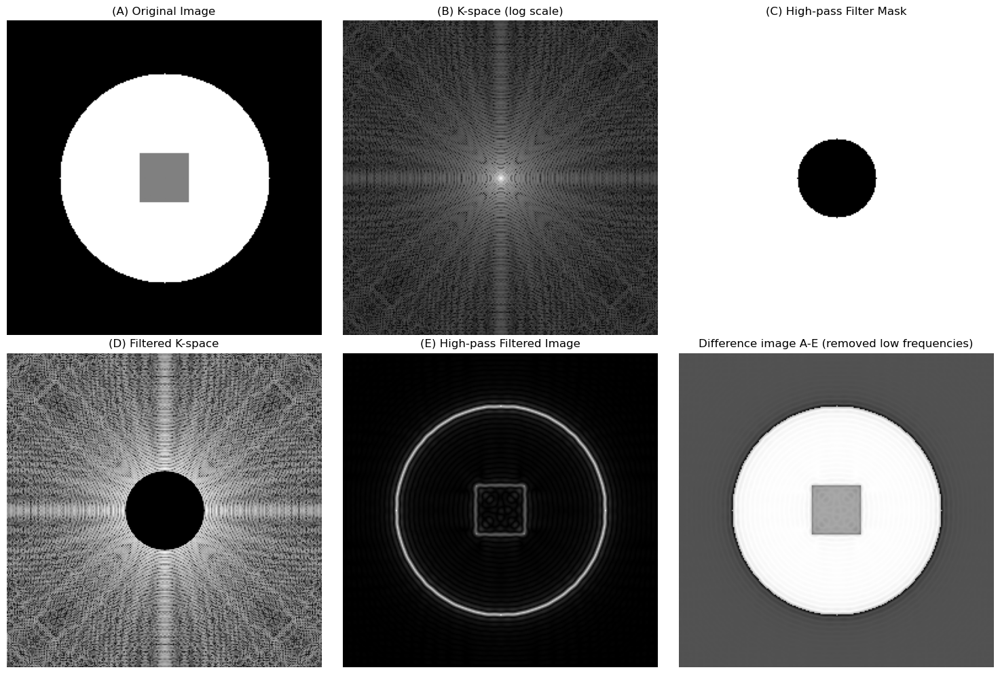


Frequency Domain Statistics:
Original k-space max magnitude: 21901.0
Filtered k-space max magnitude: 108.8
Percentage of frequencies removed: 4.9%


In [31]:
high_pass_image = eliminate_low_frequencies(phantom)


In [32]:
def eliminate_high_frequencies(image):
    """
    Demonstrate high frequency elimination in k-space
    """
    # Convert to k-space
    k_space = np.fft.fftshift(np.fft.fft2(image))
    
    # Create a mask to eliminate high frequencies
    center = np.array(k_space.shape) // 2
    mask = np.zeros_like(k_space)
    radius = 32  # Size of low frequency region to keep
    y, x = np.ogrid[-center[0]:k_space.shape[0]-center[0],
                    -center[1]:k_space.shape[1]-center[1]]
    mask_area = x*x + y*y <= radius*radius
    mask[mask_area] = 1
    
    # Apply mask and reconstruct
    k_space_filtered = k_space * mask
    image_filtered = np.abs(np.fft.ifft2(np.fft.ifftshift(k_space_filtered)))
    
    # Visualize
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original Image')
    axes[1].imshow(np.log(1 + np.abs(k_space_filtered)), cmap='gray')
    axes[1].set_title('Filtered K-space\n(High Freq. Removed)')
    axes[2].imshow(image_filtered, cmap='gray')
    axes[2].set_title('Reconstructed Image\n(Low-pass Filtered)')
    
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    
    return image_filtered

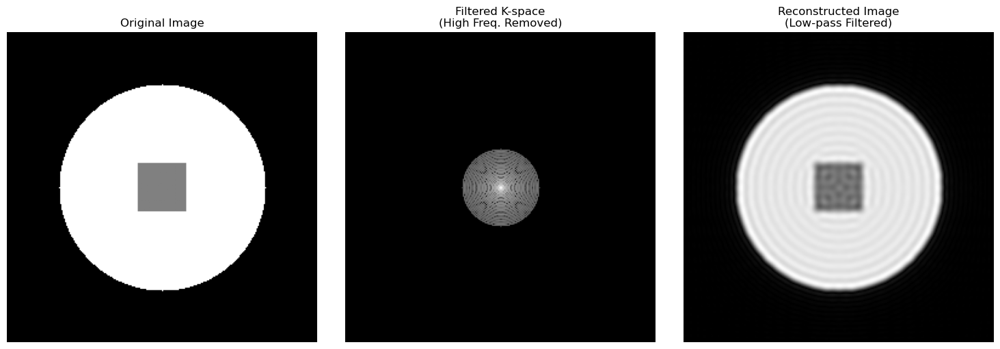

In [33]:
low_pass_image = eliminate_high_frequencies(phantom)


In [34]:
def demonstrate_kspace_undersampling(phantom, undersampling_factor=4):
    """
    Demonstrate k-space undersampling effects using the Shepp-Logan phantom
    """
    # Create figure for step-by-step visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    ax = axes.ravel()
    
    # 1. Original phantom
    ax[0].imshow(phantom, cmap='gray')
    ax[0].set_title('(A) Original Phantom (Shepp-Logan)')
    print("Step 1: Loaded phantom")
    
    # 2. Full k-space
    k_space = np.fft.fftshift(np.fft.fft2(phantom))
    # Display magnitude of k-space in log scale
    k_space_magnitude = np.log(1 + np.abs(k_space))
    ax[1].imshow(k_space_magnitude, cmap='gray')
    ax[1].set_title('(B) Full K-space (log scale)')
    print("Step 2: Computed full k-space")
    
    # 3. Create undersampling mask (real-valued)
    mask = np.zeros_like(k_space, dtype=float)
    mask[::undersampling_factor, ::undersampling_factor] = 1
    ax[2].imshow(mask, cmap='gray')
    ax[2].set_title(f'(C) Undersampling Mask (R={undersampling_factor})')
    print(f"Step 3: Created {undersampling_factor}x undersampling mask")
    
    # 4. Undersampled k-space
    k_space_under = k_space * mask
    k_space_under_magnitude = np.log(1 + np.abs(k_space_under))
    ax[3].imshow(k_space_under_magnitude, cmap='gray')
    ax[3].set_title('(D) Undersampled K-space')
    print("Step 4: Applied undersampling")
    
    # 5. Reconstructed image
    image_under = np.abs(np.fft.ifft2(np.fft.ifftshift(k_space_under)))
    ax[4].imshow(image_under, cmap='gray')
    ax[4].set_title('(E) Reconstructed Image')
    print("Step 5: Reconstructed undersampled image")
    
    # 6. Difference image
    difference = phantom - image_under
    ax[5].imshow(difference, cmap='gray')
    ax[5].set_title('(F) Difference Image: A-E')
    print("Step 6: Computed artifacts")
    
    # Turn off axes
    for a in ax:
        a.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print("\nUndersampling Statistics:")
    print(f"Acceleration factor: {undersampling_factor}x")
    print(f"Sampling points: {np.sum(mask)} of {mask.size}")
    print(f"Sampling percentage: {100 * np.sum(mask)/mask.size:.1f}%")
    print(f"RMSE: {np.sqrt(np.mean((phantom - image_under)**2)):.3f}")
    
    return image_under

Demonstrating k-space undersampling...
Step 1: Loaded phantom
Step 2: Computed full k-space
Step 3: Created 1x undersampling mask
Step 4: Applied undersampling
Step 5: Reconstructed undersampled image
Step 6: Computed artifacts


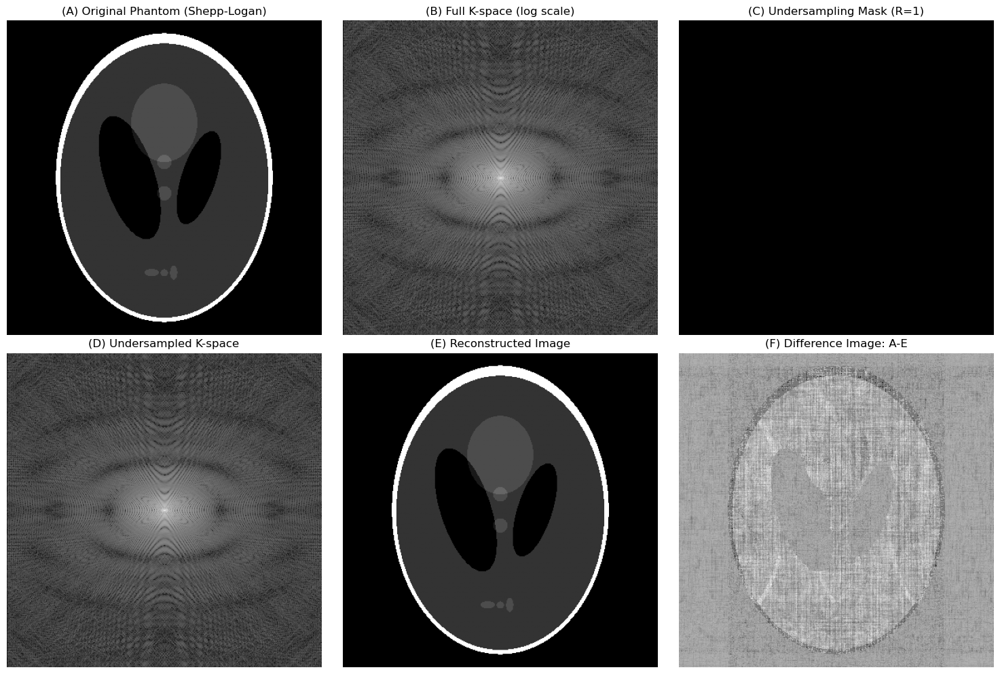


Undersampling Statistics:
Acceleration factor: 1x
Sampling points: 160000.0 of 160000
Sampling percentage: 100.0%
RMSE: 0.000


In [35]:
# Run the demo
try:
    from skimage.data import shepp_logan_phantom
    phantom = shepp_logan_phantom()
    
    print("Demonstrating k-space undersampling...")
    undersampled_image = demonstrate_kspace_undersampling(phantom, undersampling_factor=1)
    
except Exception as e:
    print(f"Error: {e}")

**REMARK:** Acceleration factor: 1x (no acceleration) gives minimal differences between original and reconstructed images (F)
Any visible patterns are likely due to numerical precision in FFT/IFFT. The statistics confirm perfect reconstruction (RMSE = 0.000)


## Display the affine matrix and ortogonal slices in 3D [MNI152](https://www.lead-dbs.org/about-the-mni-spaces) template
(The ICBM 2009c Nonlinear Symmetric template) using [OrthoSlicer3D](https://nipy.org/nibabel/reference/nibabel.viewers.html)

Image matrix: (193, 229, 193)
Affine matrix (geometry/orientation):
 [[   1.    0.    0.  -96.]
 [   0.    1.    0. -132.]
 [   0.    0.    1.  -78.]
 [   0.    0.    0.    1.]]


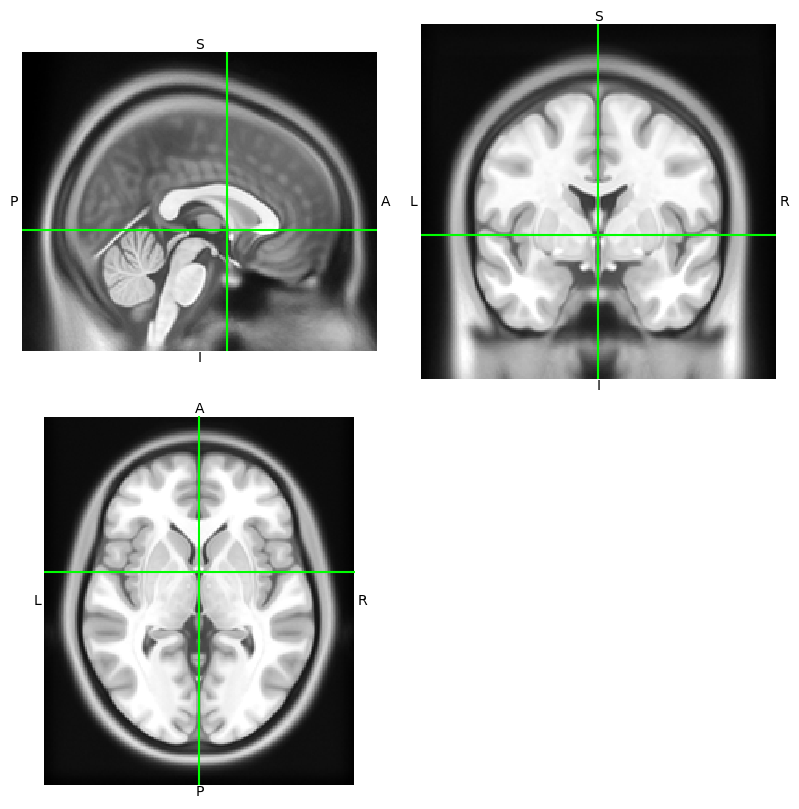

In [36]:
from nibabel.viewers import OrthoSlicer3D
mni152 = nib.load("./data/mri/mni_icbm152_t1_tal_nlin_sym_09c.nii.gz")
mni152_data = mni152.get_fdata()
print('Image matrix:', mni152_data.shape)
print('Affine matrix (geometry/orientation):\n', mni152.affine)
OrthoSlicer3D(mni152.get_fdata(), affine = mni152.affine, title = "mni152").show()

##  EXTRA:  *The affine matrix as a transformation between spaces*

We have voxel coordinates (in voxel space). We want to get scanner RAS+ coordinates (“RAS+” meaning that, in terms of the subject lying in the usual position for a brain scan, face up and head first in the scanner: left to Right; posterior to Anterior; and inferior to Superior, respectively, are all positive values in the scanner coordinate system with its origin $(0,0,0)$ in the magnetic isocenter) corresponding to the voxel coordinates. We need a coordinate transform to take us from voxel coordinates (integer values) to scanner RAS+ coordinates (float values in mm).

In general, we have some voxel space coordinate $(i,j,k)$, and we want to generate the reference space coordinate $(x,y,z)$.

Imagine we had solved this, and we had a coordinate transform function $f$ that accepts a voxel coordinate and returns a coordinate in the reference space:

$$
(x, y, z) = f(i, j, k)
$$

$f$ accepts a coordinate in the input space and returns a coordinate in the output space. In our case the input space is voxel space and the output space is scanner RAS+.

In theory $f$ could be a complicated non-linear function, but in practice, we know that the scanner collects data on a regular grid. This means that the relationship between $(i,j,k)$ and $(x,y,z)$ is linear (actually affine), and can be encoded with linear (actually *affine*) transformations comprising translations, rotations and zooms (wikipedia [linear transform](https://en.wikipedia.org/wiki/Linear_map), wikipedia [affine transform](https://en.wikipedia.org/wiki/Affine_transformation)).

Scaling (zooming) in three dimensions can be represented by a diagonal $3 \times 3$ matrix. Here’s how to zoom the first dimension by $p$, the second by $q$ and the third by $r$ units:

$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
\end{bmatrix} =
\begin{bmatrix}
p i\\
q j\\
r k\\
\end{bmatrix} =
\begin{bmatrix}
p & 0 & 0 \\
0 & q & 0 \\
0 & 0 & r \\
\end{bmatrix}
\begin{bmatrix}
i\\
j\\
k\\
\end{bmatrix}\end{split}
$$

A rotation in three dimensions can be represented as a $3 \times 3$ rotation matrix (wikipedia [rotation matrix](https://en.wikipedia.org/wiki/Rotation_matrix)). For example, here is a rotation by $\theta$ radians around the third array axis:

$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
\end{bmatrix} =
\begin{bmatrix}
\cos(\theta) &  -\sin(\theta) & 0 \\
\sin(\theta) & \cos(\theta) & 0 \\
0 & 0 & 1 \\
\end{bmatrix}
\begin{bmatrix}
i\\
j\\
k\\
\end{bmatrix}\end{split}
$$

This is a rotation by $\phi$ radians around the second array axis:

$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
\end{bmatrix} =
\begin{bmatrix}
\cos(\phi) & 0 & \sin(\phi) \\
0 & 1 & 0 \\
-\sin(\phi) & 0 & \cos(\phi) \\
\end{bmatrix}
\begin{bmatrix}
i\\
j\\
k\\
\end{bmatrix}\end{split}
$$

Zoom and rotation matrices can be combined by matrix multiplication.

Here’s a scaling of $p,q,r$ units followed by a rotation of $\theta$ radians around the third axis followed by a rotation of $\phi$ radians around the second axis:

$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
\end{bmatrix} =
\begin{bmatrix}
\cos(\phi) & 0 & \sin(\phi) \\
0 & 1 & 0 \\
-\sin(\phi) & 0 & \cos(\phi) \\
\end{bmatrix}
\begin{bmatrix}
\cos(\theta) &  -\sin(\theta) & 0 \\
\sin(\theta) & \cos(\theta) & 0 \\
0 & 0 & 1 \\
\end{bmatrix}
\begin{bmatrix}
p & 0 & 0 \\
0 & q & 0 \\
0 & 0 & r \\
\end{bmatrix}
\begin{bmatrix}
i\\
j\\
k\\
\end{bmatrix}\end{split}
$$

We can write our function f as a combination of matrix multiplication by some 3 by 3 rotation / zoom matrix M followed by addition of a 3 by 1 translation vector $(a,b,c)$

$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
\end{bmatrix} = M
\begin{bmatrix}
i\\
j\\
k\\
\end{bmatrix} +
\begin{bmatrix}
a\\
b\\
c\\
\end{bmatrix}\end{split}
$$

We could record the parameters necessary for f as the 3 by 3 matrix, M and the 3 by 1 vector (a,b,c).


In fact, the 4 by 4 image affine array does include exactly this information. If $m_{i,j}$ is the value in row $i$ column $j$ of matrix $M$, then the image affine matrix $A$ is:

$$
\begin{split}A =
\begin{bmatrix}
m_{1,1} & m_{1,2} & m_{1,3} & a \\
m_{2,1} & m_{2,2} & m_{2,3} & b \\
m_{3,1} & m_{3,2} & m_{3,3} & c \\
0 & 0 & 0 & 1 \\
\end{bmatrix}\end{split}
$$

Why the extra row of $[0,0,0,1]$? We need this row because we have rephrased the combination of rotations / zooms and translations as a transformation in *homogenous coordinates*. This is a trick that allows us to put the translation part into the same matrix as the rotations / zooms, so that both translations and rotations / zooms can be applied by matrix multiplication. In order to make this work, we have to add an extra 1 to our input and output coordinate vectors:


$$
\begin{split}\begin{bmatrix}
x\\
y\\
z\\
1\\
\end{bmatrix} =
\begin{bmatrix}
m_{1,1} & m_{1,2} & m_{1,3} & a \\
m_{2,1} & m_{2,2} & m_{2,3} & b \\
m_{3,1} & m_{3,2} & m_{3,3} & c \\
0 & 0 & 0 & 1 \\
\end{bmatrix}
\begin{bmatrix}
i\\
j\\
k\\
1\\
\end{bmatrix}\end{split}
$$

This results in the same transformation as applying $M$ and $(a,b,c)$ separately. One advantage of encoding transformations this way is that we can combine two sets of [rotations, zooms, translations] by matrix multiplication of the two corresponding affine matrices.

## CHECK OUT (in addition to the explanations given above):
>
> - *Coordinate systems and affine transformations in medical imaging (e.g. [nibabel](http://nipy.org/nibabel/coordinate_systems.html) / [nilearn](http://nilearn.github.io/auto_examples/04_manipulating_images/plot_affine_transformation.html))*
> - *Converting images in DICOM format (from the scanner) to the NIFTI format for processing (e.g. [dcm2nii](https://www.nitrc.org/plugins/mwiki/index.php/dcm2nii:MainPage) og [dcm2niix](https://github.com/rordenlab/dcm2niix))*

## $\rightarrow$ Your turn!

Make code that display the middle slice in the the 3D MNI152 template

**HINT:** (from the [Nibabel](https://nipy.org/nibabel/coordinate_systems.html) documentation)

Load the MNI152 template:
```
mni152 = nib.load("./data/mni_icbm152_t1_tal_nlin_sym_09c.nii.gz")
```

Modify the following:
```code
>>> import matplotlib.pyplot as plt
>>> def show_slices(slices):
...    """ Function to display row of image slices """
...    fig, axes = plt.subplots(1, len(slices))
...    for i, slice in enumerate(slices):
...        axes[i].imshow(slice.T, cmap="gray", origin="lower")

>>> anat_img = nib.load('downloads/someones_anatomy.nii.gz')
>>> anat_img_data = anat_img.get_fdata()
>>> anat_img_data.shape
(57, 67, 56)
>>> show_slices([anat_img_data[28, :, :],
...              anat_img_data[:, 33, :],
...              anat_img_data[:, :, 28]])
>>> plt.suptitle("Center slices for anatomical image")
>>> plt.show()
````
The middle slices can be found by e.g.:
```
np.round(np.array(anat_img_data.shape) / 2)
```
or, by integer division
```
np.array(anat_img_data.shape) // 2
```
or, by mental arithmetic ...

In [37]:
# Here is my code:



# Modify header information before the multispectral image is saved 
(for geometric correspondance between image date and training masks)

### Display the affine matrix of the  2D FLASH channel (img1) using [OrthoSlicer3D](https://nipy.org/nibabel/reference/nibabel.viewers.html) 

Affine matrix (geometry/orientation):
 [[   0.            0.            1.39999998    0.        ]
 [  -1.            0.           -0.          256.        ]
 [   0.            1.            0.         -511.        ]
 [   0.            0.            0.            1.        ]]


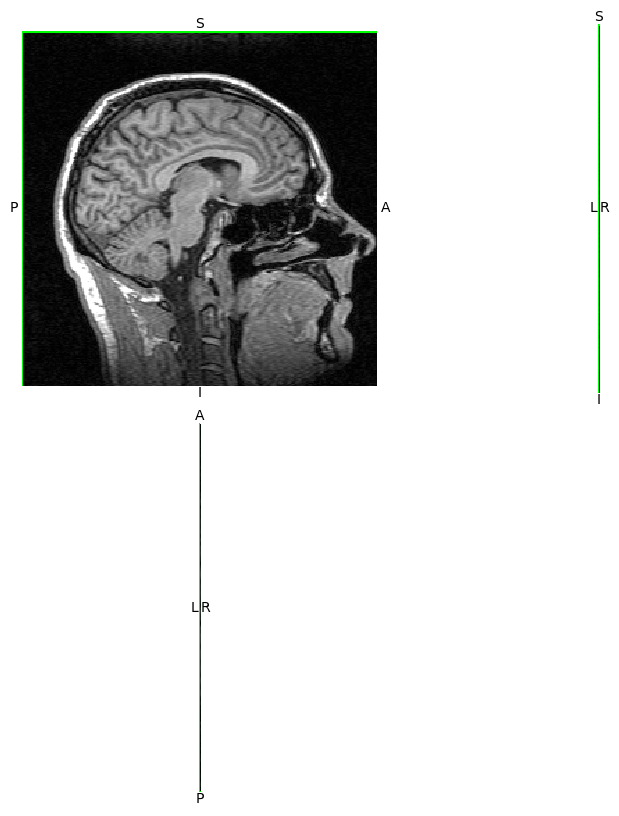

In [38]:
from nibabel.viewers import OrthoSlicer3D
print('Affine matrix (geometry/orientation):\n', img1.affine)
OrthoSlicer3D(images[0].get_fdata(), affine = images[0].affine).show()

## Editing the affine matrix related to the NIFTI image in order to manipulate the geometry
Notice: the image data as such i.e. the pixel-wise signal intensity values, are preserved

**Reverse A(nterior)-P(osterior) orientation such that that the nose (anterior) is pointing to the left in the figure**

Show the original orientation using plotting functions from the `nilearn` library (suppress multiple warnings)

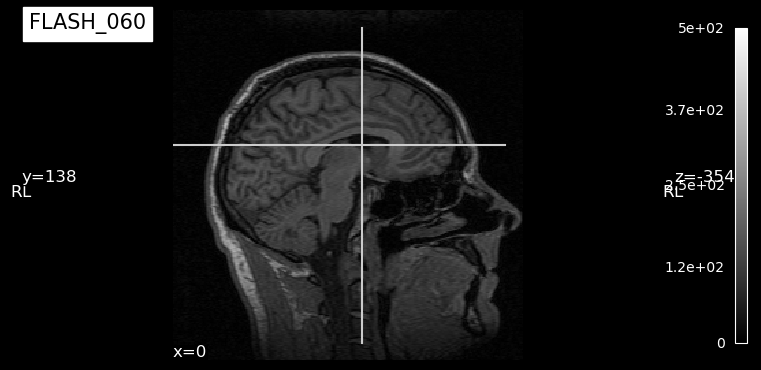

In [39]:
%matplotlib inline
warnings.filterwarnings(action='ignore')  # 'ignore' 'once'
plotting.plot_anat(images[0], title="FLASH_060")
plotting.show()

In our case we will make a reflection along the x-axis, i.e. change sign in the corresponding element in the affine $4 \times 4$ matrix:

In [40]:
aff = img_mult.affine
print('aff original:\n', aff)
aff_new = aff.copy()
aff_new[1][0]=1  # Change sign
print('\n aff_new:\n', aff_new)
img_new = nib.Nifti1Pair(img_mult.get_fdata(), aff_new)
print('\n img_new.affine:\n', img_new.affine)

aff original:
 [[   0.            0.            1.39999998    0.        ]
 [  -1.            0.           -0.          256.        ]
 [   0.            1.            0.         -511.        ]
 [   0.            0.            0.            1.        ]]

 aff_new:
 [[   0.            0.            1.39999998    0.        ]
 [   1.            0.           -0.          256.        ]
 [   0.            1.            0.         -511.        ]
 [   0.            0.            0.            1.        ]]

 img_new.affine:
 [[   0.            0.            1.39999998    0.        ]
 [   1.            0.           -0.          256.        ]
 [   0.            1.            0.         -511.        ]
 [   0.            0.            0.            1.        ]]


Checking the new orientation after changing sign corresponding the the $x$-direction in the affine matrix.

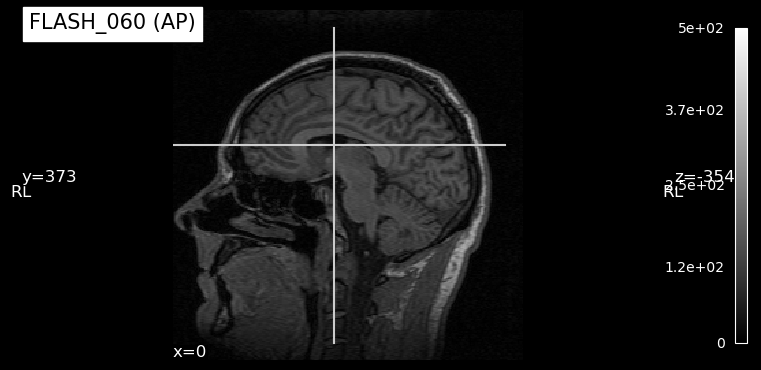

In [41]:
%matplotlib inline
img1_new = nib.Nifti1Pair(img1.get_fdata(), aff_new)
plotting.plot_anat(img1_new, title="%s_060 (AP)" % (chn_names[0]))
plotting.show()

We also check for the DESS channel:

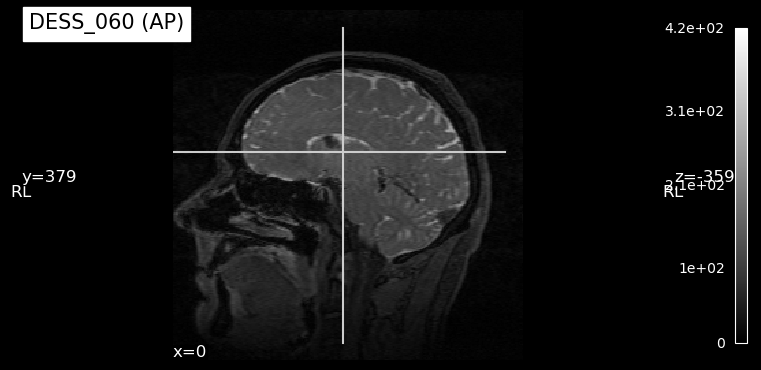

In [42]:
img2_new = nib.Nifti1Pair(img2.get_fdata(), aff_new)
plotting.plot_anat(img2_new, title="%s_060 (AP)" % (chn_names[1]))
plotting.show()

or, check by using the `OrthoSlicer3D`:

Affine matrix (geometry/orientation):
 [[   0.            0.            1.39999998    0.        ]
 [  -1.            0.           -0.          256.        ]
 [   0.            1.            0.         -511.        ]
 [   0.            0.            0.            1.        ]]


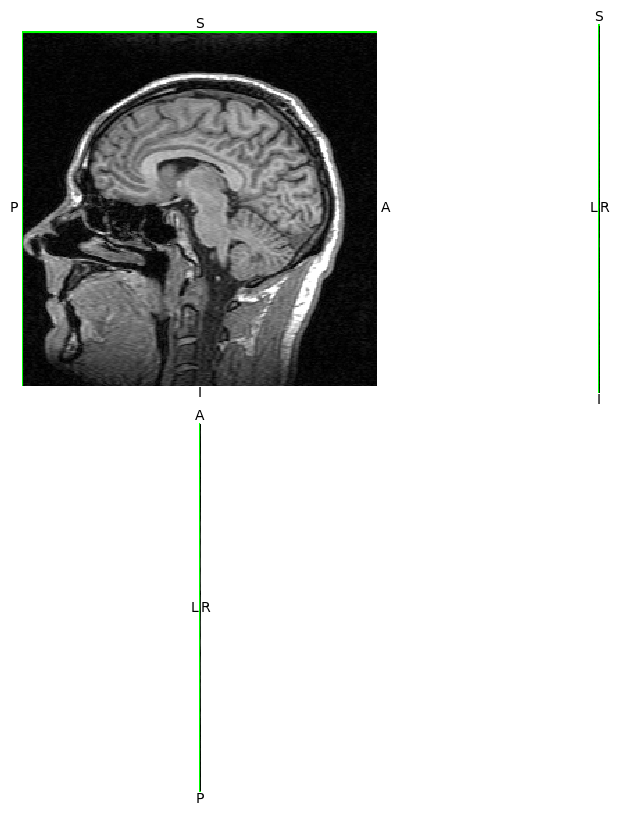

In [43]:
print('Affine matrix (geometry/orientation):\n', img1.affine)
OrthoSlicer3D(img1.get_fdata(), affine = aff_new).show()

## Finally, we define the multispectral image `img` with the new affine in the header

Remember, the original image was denoted `img_mult`

In [44]:
img = nib.Nifti1Pair(img_mult.get_fdata(), aff_new)

### We might also incorporate a new affine matrix (? by borrowing from another NIFTI image)  

Here: **new 4×4 affine matrix** (by trial and error, or by careful analysis) and incorporate in the new header of the NIFTI image

In [45]:
aff_new2 = np.array([
    [   1.  ,    0  ,    0. ,   0.  ],
    [   0.  ,    1. ,    0. ,   0.  ],
    [   0.  ,    0. ,    1.4,   0.  ],
    [   0.  ,    0. ,    0. ,   1.  ]
])

Check with aff_new2: (note that the figure labeling of orientations in anatomical space (P-A, S-I, L-R) are no longer valid) 

Affine matrix (geometry/orientation):
 [[1.  0.  0.  0. ]
 [0.  1.  0.  0. ]
 [0.  0.  1.4 0. ]
 [0.  0.  0.  1. ]]


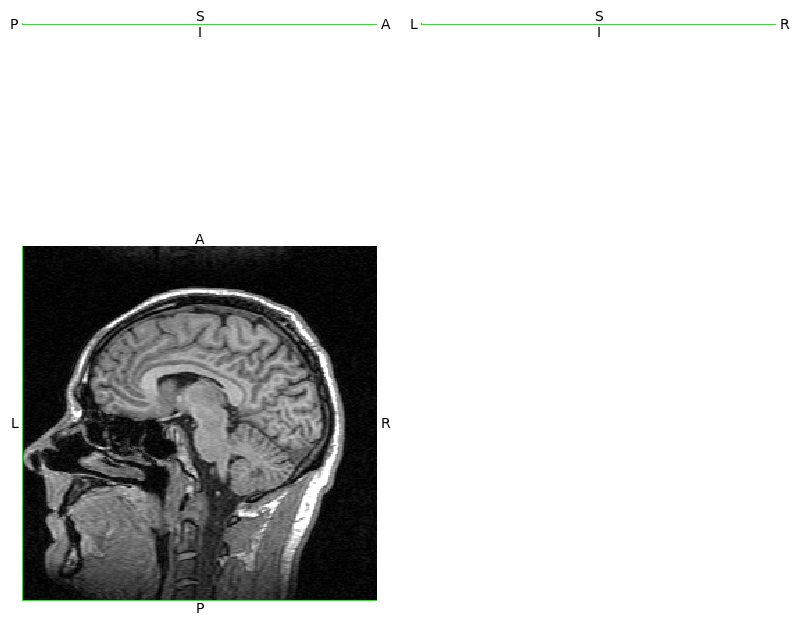

In [46]:
print('Affine matrix (geometry/orientation):\n', aff_new2)
OrthoSlicer3D(images[0].get_fdata(), affine = aff_new2).show()

> **$\rightarrow$ Your turn!**
>
> - Design an affine matrix `aff_new3`that turns the image upside-down and display the result

> Hint:
```python
aff1 = img1_new.affine
aff_new3 = aff1.copy()
aff_new3[2][1]=-1  # Change sign
img1_ud = nib.Nifti1Pair(img1.get_data(), aff_new3)
plotting.plot_anat(img1_ud, title="flash_060 (upside-down)")
plotting.show()
```
or,
```
print('Affine matrix (geometry/orientation):\n', aff_new3)
OrthoSlicer3D(images[0].get_fdata(), affine = aff_new3).show()
```

In [47]:
# Your code:


## Display two consecutive channels in the multispectral image

Choose a $k$ - what are the valid values of $k$?

In [48]:
img.shape

(256, 256, 1, 4)

In [49]:
k= 0
ima = np.squeeze(img.get_fdata()[:,:,0,k])

ima.shape

(256, 256)

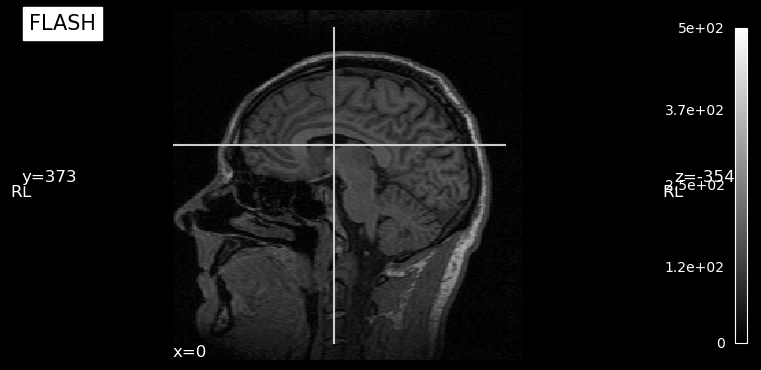

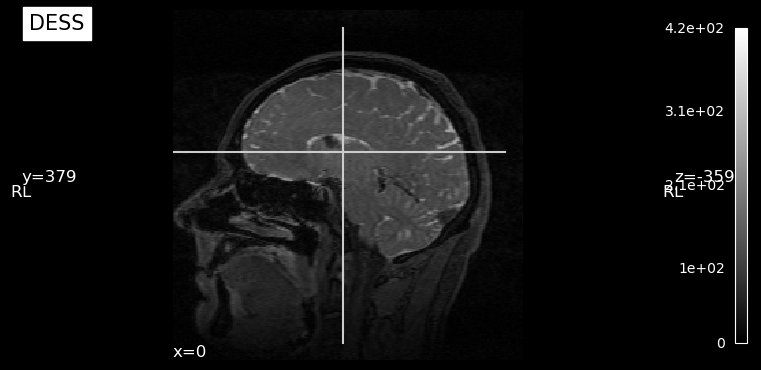

In [50]:
%matplotlib inline
k=0
#ima = image.index_img(img, k)
slice_data = np.squeeze(img.get_fdata()[:,:,0,k])
# Nibabel does not support plotting of 2D data, so we need to reshape it
slice_data = slice_data.reshape(slice_data.shape[0], slice_data.shape[1], 1) 
# Make a nibabel image object
slice_img = nib.Nifti1Pair(slice_data, img.affine)
# Plot the image
plotting.plot_anat(slice_img, title=chn_names[k])
#ima = image.index_img(img, k+1)
slice_data = np.squeeze(img.get_fdata()[:,:,0,k+1]) 
slice_data = slice_data.reshape(slice_data.shape[0], slice_data.shape[1], 1) 
slice_img = nib.Nifti1Pair(slice_data, img.affine)
plotting.plot_anat(slice_img, title=chn_names[k+1])
plotting.show()

# Write the multispectral image to disk for later use

In [51]:
fn_multispectral = './data/multispectral_mri.nii.gz'
nib.save(img, fn_multispectral)

## Print interesting characteristics of the NIFTI image

In [52]:
print('shape of image = ', img.header.get_data_shape())
print('units = ', img.header.get_xyzt_units())
print('voxel size = ', img.header.get_zooms())
print('dtype = %s' % img.header.get_data_dtype())
data = img.get_fdata()
print('min = %.1f' % data.min())
print('max = %.1f' % data.max())
print('number of channels =', img.shape[-1])
# Collaps the singular (z-)dimension and convert to uint16
dat = np.uint16(data.squeeze())
print('shape of 2D+spectral dat = ',dat.shape)
print('dtype of 2D+spectral dat = ',dat.dtype)

shape of image =  (256, 256, 1, 4)
units =  ('unknown', 'unknown')
voxel size =  (np.float32(1.0), np.float32(1.0), np.float32(1.4), np.float32(1.0))
dtype = float64
min = 0.0
max = 493.0
number of channels = 4
shape of 2D+spectral dat =  (256, 256, 4)
dtype of 2D+spectral dat =  uint16


## Display the multispectral image as separate channel images in a 2 x 2 matrix plot 

How to position a [suptitle](https://stackoverflow.com/questions/55767312/how-to-position-suptitle)?

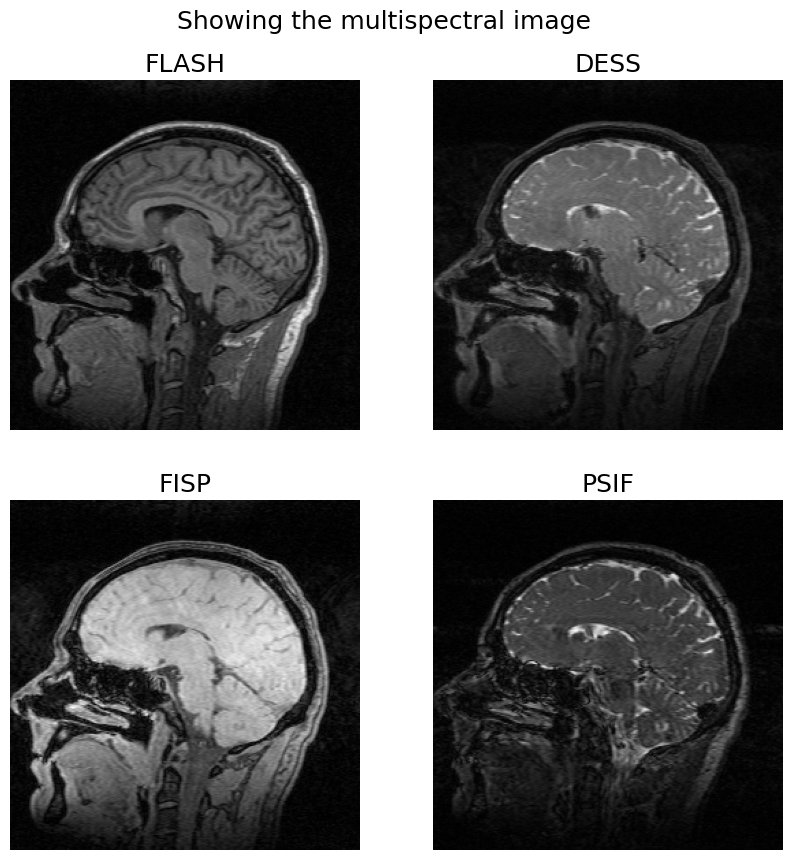

In [53]:
fig = plt.figure('Showing the multispectral image', figsize = [10, 10])
plt.tight_layout
plt.subplot(2, 2, 1).set_axis_off(), plt.title(chn_names[0], fontsize=18)
plt.imshow(dat[:, :, 0].T, cmap='gray', origin='lower')  # .T for transpose to correct orientation
plt.subplot(2, 2, 2).set_axis_off(), plt.title(chn_names[1], fontsize=18)
plt.imshow(dat[:, :, 1].T, cmap='gray', origin='lower')
plt.subplot(2, 2, 3).set_axis_off(), plt.title(chn_names[2], fontsize=18)
plt.imshow(dat[:, :, 2].T, cmap='gray', origin='lower')
plt.subplot(2, 2, 4).set_axis_off(), plt.title(chn_names[3], fontsize=18)
plt.imshow(dat[:, :, 3].T, cmap='gray', origin='lower')
plt.suptitle("Showing the multispectral image", y=0.95, fontsize=18)
plt.show()

# If you want to store this figure on disk, uncomment the following and adjust the path.
# You could also consider to increase the figsize ...

#fig.savefig('%s/prj/BMED365/results/flash_dess_fisp_psif_channel_images.png' % (home),
#            transparent=False, dpi=300, bbox_inches="tight")

**Alternatively:**

In [54]:
channels = ['FLASH', 'DESS', 'FISP', 'PSIF']

In [55]:
images = [imageio.imread(f'./assets/{channel.lower()}_060.dcm') for channel in channels] 

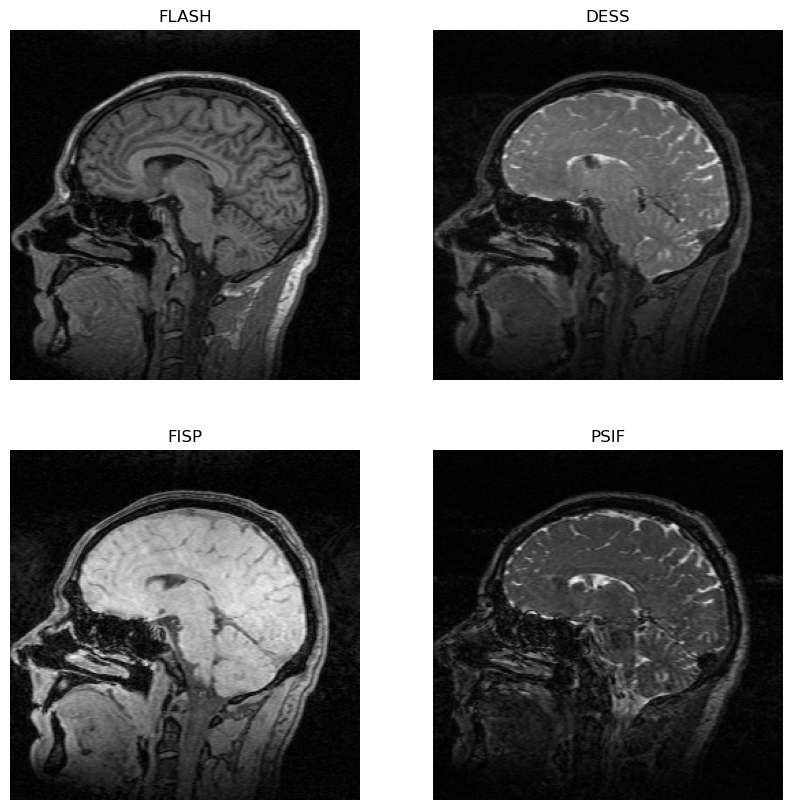

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
ax = axes.ravel()

for i, im in enumerate(images):
    ax[i].imshow(im, cmap='gray')
    ax[i].set_title(channels[i])
    ax[i].axis('off')

plt.show()

## Display multichannel brain tumor data from the BraTS 2020 challenge

**Segmentation (HD-GLIO) info:**
- **CE**s: contrast-enhancing tumours (mask=1)
- **NE**s (non-enhancing T2-signal abnormalities, mask=2): defined as T2-FLAIR hyperintense abnormality excluding the contrast-enhancing and necrotic portion of the tumour, resection cavity, and obvious leukoaraiosis.
- Delineated volumetrically by experienced neuroradiologists
- We defined **tumour progression** as an increase in tumour volume (compared with baseline or best response) in either CE tumour or NEs, beyond a minimal tumour volume of 1 cm³; or occurrence of a new CE lesion outside of the CE tumour volume from the previous MRI scan (identified automatically using dedicated algorithms with the respective segmentation masks over time as input (cf. the appendix)

In [57]:
# AD HOC colormap for HD-GLIO  (CE, NE)-segmentation overlay
colors = [(1, 0, 0), (0, 0, 1), (0, 1, 0)]  # R -> B -> G
n_bins = [2, 3, 6, 10, 100]  # Discretizes the interpolation into bins
cmap_name = 'my_cm'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins[0])

#### Calculate the CE (=1) and NE (=2) volumes
using `np.where()` and `np.prod(vox_size)`

In [58]:
def hdglio_ce_ne_volumes(fn_segm):
    
    
    img = nib.load(fn_segm)
    vox_size = img.header.get_zooms()
    vox_vol = np.prod(vox_size)
    data = img.get_fdata()
        
    # Find voxel locations (CE and NE roi) corresponding to hd_glio_pred segmentations  
    
    CE_roi = np.where(data == 1) 
    X_CE = np.asarray(data[CE_roi[0][:],CE_roi[1][:],CE_roi[2][:]]) # The MRI channel signal intensities in NE
    CE_vol = (len(X_CE.flatten())*vox_vol).astype(int)
    
    NE_roi = np.where(data == 2) 
    X_NE = np.asarray(data[NE_roi[0][:],NE_roi[1][:],NE_roi[2][:]]) # The MRI channel signal intensities in CE
    NE_vol = (len(X_NE.flatten())*vox_vol).astype(int)
            
    return vox_vol, CE_vol, NE_vol

In [59]:
## Calculate the CE (=1) and NE (=2) volumes using np.where() and np.prod(vox_size
fn_segm = './data/mri/BraTS20/BraTS20_Training_002_HDGlioSeg.nii.gz'
vox_vol, CE_vol, NE_vol = hdglio_ce_ne_volumes(fn_segm)
print(f'BraTS20_Training_002: CE-volume={CE_vol}, NE-volume={NE_vol}, vox_vol={vox_vol} (volumes in microL)\n')

BraTS20_Training_002: CE-volume=59379, NE-volume=6999, vox_vol=1.0 (volumes in microL)



**Inspect channels that are brain-extracted and coregistered**

In [60]:
chns = ['T1', 'CT1', 'T2', 'FLAIR']
chnsbrats = ['t1', 't1ce', 't2', 'flair']

In [61]:
# Cross cut coordinates, and dim values (emperically defined)
x, y, z = -102, 114, 55
dims = [-0.05, -0.7, -0.7, -0.7]

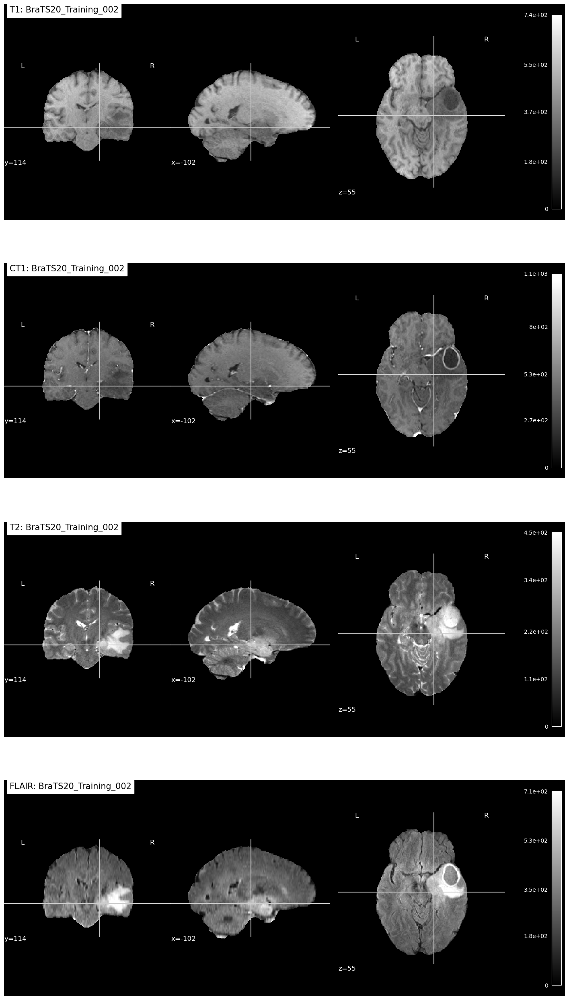

In [62]:
fig, axes  = plt.subplots(4, 1, figsize=(18,32))
k=0
for ax in axes.flatten():
    CH = chns[k]
    chn = chnsbrats[k]
    fn_inp = './data/mri/BraTS20/BraTS20_Training_002_%s.nii.gz' % chn
    tit = '%s: BraTS20_Training_002' % CH
    img = nib.load(fn_inp)
    plotting.plot_anat(img, axes = ax, title=tit, cmap="gray", dim=dims[k], cut_coords = (x, y, z))
    k=k+1
plt.show()

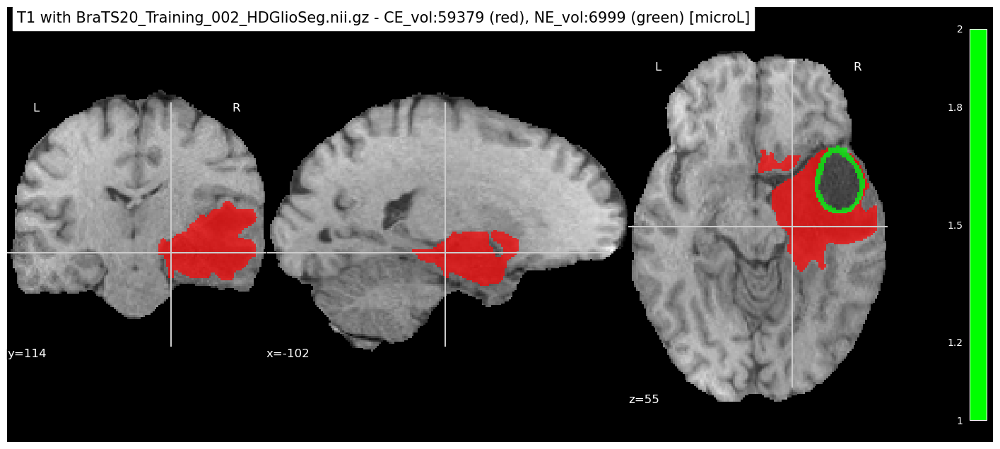

In [63]:
## Inspect HD-GLIO segmentation results
CH = 'T1'
chn = 't1'
fn_bg = './data/mri/BraTS20/BraTS20_Training_002_%s.nii.gz' % chn 
fn_segm = './data/mri/BraTS20/BraTS20_Training_002_HDGlioSeg.nii.gz'
bg_img = nib.load(fn_bg)
segm_img = nib.load(fn_segm)
tit = '%s with BraTS20_Training_002_HDGlioSeg.nii.gz - CE_vol:%d (red), NE_vol:%d (green) [microL]' % (CH, CE_vol, NE_vol )
fig, ax  = plt.subplots(1, 1, figsize=(18,8))
plotting.plot_roi(segm_img, bg_img, axes = ax, title=tit, cmap=cm, dim= -0.05, cut_coords = (x, y, z))
plt.show()